# 02 Data Cleaning



In [2]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = "../reports/figures/"
RAW = "../data/raw/Dataset.xlsx"
from src.cleaning import (CHANNEL_COLS, TARGET_COL, EXTERNAL_COLS, load_raw, standardise_columns, fix_dtypes,
                          remove_duplicates, handle_missing, reconcile_total_spend, detect_outliers,
                          add_outlier_count, drop_constant_columns)

## Step 1: column names and data types

In [3]:
raw = load_raw(RAW)
df = standardise_columns(raw)
print("Column names changed:", list(raw.columns) != list(df.columns))
df = fix_dtypes(df)
df.dtypes.to_frame("dtype").T

Column names changed: False


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,total_ad_spend_lkr,sales_revenue_lkr,units_sold,impressions,clicks,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,data_type
dtype,datetime64[us],string,string,string,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,int64,string


## Step 2: duplicates

In [4]:
df, n_dups = remove_duplicates(df)
print("Duplicate rows or duplicate months removed:", n_dups)

Duplicate rows or duplicate months removed: 0


## Step 3: missing values

No cell is missing. The code still handles gaps so that the pipeline can be rerun on new data: a row without a target value is dropped and other numeric gaps are filled by linear interpolation in time order.

In [5]:
df, missing = handle_missing(df)
print("Missing values found:", missing or "none")
print("Missing cells after handling:", int(df.isna().sum().sum()))

Missing values found: none
Missing cells after handling: 0


## Step 4: total spend

In [6]:
before = df["total_ad_spend_lkr"].copy()
df, n_changed = reconcile_total_spend(df)
print("Rows where the total differed from the channel sum:", n_changed)
print("Largest change (LKR):", (df["total_ad_spend_lkr"] - before).abs().max())

Rows where the total differed from the channel sum: 16
Largest change (LKR): 2


The total differed from the sum of the six channels by 1 or 2 LKR in some rows. This is rounding, so the total was replaced by the exact sum. A difference above 5 LKR would stop the pipeline with an error.

## Step 5: outliers

A value is flagged if it lies outside 1.5 times the IQR from the quartiles or has an absolute z-score above 3. With 36 rows nothing is removed or capped.

In [7]:
scan_cols = CHANNEL_COLS + [TARGET_COL, "units_sold"] + EXTERNAL_COLS
outliers = detect_outliers(df, scan_cols)
outliers

,month,column,value,iqr_lower,iqr_upper,z_score,rule
0,2023-01-01,sales_revenue_lkr,"68,727,157.000","70,114,068.625","100,057,853.625",-2.172,IQR
1,2023-04-01,sales_revenue_lkr,"100,712,194.000","70,114,068.625","100,057,853.625",2.073,IQR
2,2024-08-01,sales_revenue_lkr,"69,887,847.000","70,114,068.625","100,057,853.625",-2.018,IQR
3,2023-12-01,seasonal_demand_index,1.240,0.841,1.231,2.214,IQR
4,2024-12-01,seasonal_demand_index,1.240,0.841,1.231,2.214,IQR
5,2025-12-01,seasonal_demand_index,1.240,0.841,1.231,2.214,IQR


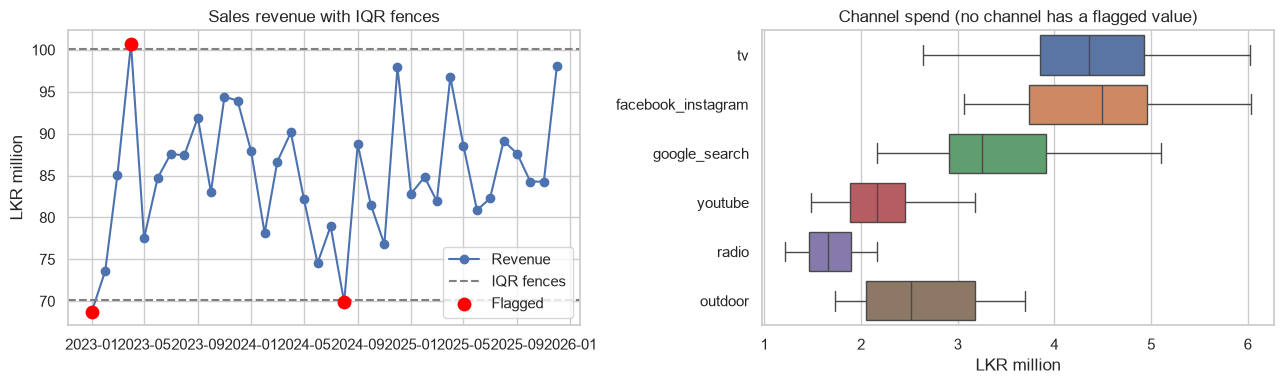

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df["month"], df[TARGET_COL] / 1e6, marker="o", label="Revenue")
q1, q3 = df[TARGET_COL].quantile([.25, .75])
iqr = q3 - q1
ax[0].axhline((q3 + 1.5 * iqr) / 1e6, ls="--", c="grey", label="IQR fences")
ax[0].axhline((q1 - 1.5 * iqr) / 1e6, ls="--", c="grey")
flag = outliers[outliers["column"] == TARGET_COL]
ax[0].scatter(flag["month"], flag["value"] / 1e6, c="red", s=80, zorder=5, label="Flagged")
ax[0].set(title="Sales revenue with IQR fences", ylabel="LKR million")
ax[0].legend()
spend = df[CHANNEL_COLS].div(1e6).rename(columns=lambda c: c.replace("_spend_lkr", ""))
sns.boxplot(data=spend, ax=ax[1], orient="h")
ax[1].set(title="Channel spend (no channel has a flagged value)", xlabel="LKR million")
plt.tight_layout()
plt.savefig(FIG + "02_outlier_check.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
context_cols = [TARGET_COL, "promotion_discount_pct", "seasonal_demand_index", "public_holiday_count"]
df.set_index("month").loc[outliers["month"].unique(), context_cols]

,sales_revenue_lkr,promotion_discount_pct,seasonal_demand_index,public_holiday_count
month,,,,
2023-01-01,68727157,7.270,1.080,2
2023-04-01,100712194,21.520,1.190,6
2024-08-01,69887847,16.700,0.990,4
2023-12-01,93935346,12.230,1.240,7
2024-12-01,97913978,28.220,1.240,6
2025-12-01,98107722,12.470,1.240,7


Decision: all flagged values are kept.

* Revenue: 2023-01 (68.7 m) and 2024-08 (69.9 m) are just below the lower fence, and 2023-04 (100.7 m) is just above the upper fence. Their absolute z-scores are between 2.0 and 2.2, so none is extreme. April 2023 had a 21.5% promotion and 6 public holidays. August 2024 was low although the promotion was 16.7%, which shows that promotion alone does not decide revenue. There is no sign of a data entry error.
* `seasonal_demand_index` is 1.24 in every December. This is the festive peak in the data, not an error.
* No channel spend, price, exchange rate or sentiment value is flagged.

The number of flags in each month is stored in `n_outlier_flags`, so a model can be rerun without these months as a sensitivity check.

In [10]:
df = add_outlier_count(df, outliers)
print("Months with at least one flag:", int((df["n_outlier_flags"] > 0).sum()))

Months with at least one flag: 6


## Step 6: constant columns and saving

In [11]:
df, dropped = drop_constant_columns(df)
print("Dropped:", dropped)
df.to_csv("../data/processed/mmm_cleaned.csv", index=False)
outliers.to_csv("../data/processed/outlier_flags.csv", index=False)
print("Saved mmm_cleaned.csv", df.shape)
df.head()

Dropped: ['country', 'brand_category', 'region_scope', 'data_type']
Saved mmm_cleaned.csv (36, 22)


,month,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,total_ad_spend_lkr,sales_revenue_lkr,units_sold,impressions,clicks,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,n_outlier_flags
0,2023-01-01,4274762,3890003,2467793,1836858,1700676,1813444,15983536,68727157,125509,869144666,30195201,1210051,0.998,7.270,49.600,56.800,324.420,1.000,1.080,2,1
1,2023-02-01,4023574,5062635,2962576,2254198,1922384,2941194,19166561,73594547,116120,2087093794,37317742,664746,1.017,9.470,51.000,58.400,335.920,1.012,0.960,6,0
2,2023-03-01,5359091,3746337,4080535,2363737,1720670,2063917,19334287,85063287,151114,1313850185,21983955,380625,1.011,6.830,45.900,60.600,328.660,1.024,1.000,2,0
3,2023-04-01,5102550,3690115,3390558,2595121,1217450,3091430,19087224,100712194,187415,1213988281,29151544,1228413,1.017,21.520,31.200,54.500,325.600,1.037,1.190,6,1
4,2023-05-01,4972723,5333813,3240078,2343364,1568285,3525300,20983563,77502288,168095,1453687593,25496654,562986,1.014,1.950,53.000,56.500,330.030,1.049,1.100,3,0


In [12]:
import json
log = {"rows_raw": len(raw), "rows_clean": len(df), "duplicates_removed": n_dups,
       "missing_found": missing, "total_spend_rows_adjusted": n_changed,
       "outlier_flags": len(outliers), "constant_columns_dropped": dropped}
print(json.dumps(log, indent=2, default=str))

{
  "rows_raw": 36,
  "rows_clean": 36,
  "duplicates_removed": 0,
  "missing_found": {},
  "total_spend_rows_adjusted": 16,
  "outlier_flags": 6,
  "constant_columns_dropped": [
    "country",
    "brand_category",
    "region_scope",
    "data_type"
  ]
}
